# Task D — Clinical review, one step per cell

CDB601220 · Week 3. Work through the cells from top to bottom. Every dataset is loaded from the **data/** folder beside this notebook. All data are synthetic, supplied with the assignment. Charts and written answers stay inside the notebook; no output files are created.

## 1. Import libraries and locate the data folder

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

DATA = Path('data')
assert DATA.is_dir(), 'Open this notebook inside task3, beside the data folder.'
sns.set_theme(style='whitegrid', palette=['#0072B2', '#D55E00', '#009E73'])
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.ioff()
BLUE, ORANGE, GREEN = '#0072B2', '#D55E00', '#009E73'
SOURCE = 'Source: synthetic CDB601220 Week 3 assignment data.'

## 2. Load the original patient records

In [2]:
raw = pd.read_csv(DATA / 'vitals_10k.csv')
print('Loaded records:', len(raw))

Loaded records: 10000


### Inspect 1/4: types and non-null counts

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      10000 non-null  str    
 1   admit_date      10000 non-null  str    
 2   ward            10000 non-null  str    
 3   age             10000 non-null  int64  
 4   sex             10000 non-null  str    
 5   systolic        10000 non-null  int64  
 6   diastolic       10000 non-null  int64  
 7   map_mmhg        10000 non-null  float64
 8   heart_rate      10000 non-null  int64  
 9   spo2            10000 non-null  int64  
 10  bmi             10000 non-null  float64
 11  chol_mmol_l     10000 non-null  float64
 12  glucose_mmol_l  10000 non-null  float64
 13  los_days        10000 non-null  float64
 14  readmitted_30d  10000 non-null  int64  
 15  risk_score      10000 non-null  float64
dtypes: float64(6), int64(6), str(4)
memory usage: 1.5 MB


### Inspect 2/4: numeric distributions

In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,10000.0,58.113800,16.639728,18.0,47.000000,58.0000,69.0000,97.00
systolic,10000.0,137.656700,22.597192,92.0,119.000000,128.0000,160.0000,199.00
diastolic,10000.0,79.628200,13.134109,45.0,69.000000,78.0000,90.0000,125.00
map_mmhg,10000.0,98.970690,15.830095,65.3,85.700000,94.3000,113.7000,149.70
heart_rate,10000.0,78.833100,20.557021,0.0,69.000000,78.0000,87.0000,415.00
spo2,10000.0,96.724000,2.239671,81.0,96.000000,97.0000,98.0000,100.00
bmi,10000.0,66.177040,190.996849,0.0,24.000000,27.6000,31.2000,999.00
chol_mmol_l,10000.0,4.823818,1.010410,2.1,4.140000,4.8200,5.5100,8.79
glucose_mmol_l,10000.0,6.550060,1.145823,5.1,5.700000,6.3000,7.1000,13.90
los_days,10000.0,2.309091,8.923347,0.0,0.610000,1.3800,2.5700,273.65


### Inspect 3/4: ward spellings

In [5]:
raw.ward.value_counts()

ward
General Medicine    1356
general medicine    1353
Gen Medicine        1309
CARDIOLOGY           914
cardio               886
Cardiology           882
Day Surgery          749
Day-Surgery          730
Intensive Care       486
ICU                  480
 I.C.U               442
icu                  413
Name: count, dtype: int64

### Inspect 4/4: admission date formats

In [6]:
raw.admit_date.head(20).tolist()

['2026-01-19',
 '08-Mar-2026',
 '2026-02-26',
 '27/02/2026',
 '09/01/2026',
 '01-Apr-2026',
 '17-Apr-2026',
 '24-Mar-2026',
 '14-Apr-2026',
 '02-Jan-2026',
 '10/03/2026',
 '10/02/2026',
 '12-Apr-2026',
 '29/03/2026',
 '17-Apr-2026',
 '12/02/2026',
 '2026-03-28',
 '2026-02-03',
 '11-Apr-2026',
 '08/01/2026']

The first inspection reveals mixed date formats, multiple ward spellings, BMI codes 0/999 and invalid heart rates. Further checks address derived MAP, mixed systolic populations, skewed LOS/glucose, bounded SpO₂ and the risk-score ratio. These are not all deletion rules: real distributional features are retained.

## 3. Make a working copy and check identifiers

In [7]:
cleaned = raw.copy()
cleaning_rows = []
print('Duplicate patient IDs:', raw.patient_id.duplicated().sum())
assert raw.patient_id.is_unique

Duplicate patient IDs: 0


### Standardize the ward names

In [8]:
ward_map = {'general medicine':'General Medicine', 'gen medicine':'General Medicine',
            'cardiology':'Cardiology', 'cardio':'Cardiology', 'day surgery':'Day Surgery',
            'day-surgery':'Day Surgery', 'intensive care':'ICU', 'icu':'ICU', 'i.c.u':'ICU'}
cleaned['ward_clean'] = cleaned.ward.str.strip().str.lower().map(ward_map)
assert cleaned.ward_clean.notna().all() and cleaned.ward_clean.nunique() == 4
display(cleaned.ward_clean.value_counts())
cleaning_rows.append({'rule':'12 ward spellings → 4 names', 'affected':int((cleaned.ward != cleaned.ward_clean).sum()), 'rows_removed':0})

ward_clean
General Medicine    4018
Cardiology          2682
ICU                 1821
Day Surgery         1479
Name: count, dtype: int64

### Parse the three explicit date formats

In [9]:
cleaned['admit_dt'] = pd.Series(pd.NaT, index=cleaned.index, dtype='datetime64[ns]')
for fmt in ['%Y-%m-%d', '%d/%m/%Y', '%d-%b-%Y']:
    parsed = pd.to_datetime(cleaned.admit_date, format=fmt, errors='coerce')
    cleaned['admit_dt'] = cleaned.admit_dt.fillna(parsed)
assert cleaned.admit_dt.notna().all()
display(cleaned[['admit_date','admit_dt']].head(20))
cleaning_rows.append({'rule':'Parse 3 date formats without month/day guessing', 'affected':len(cleaned), 'rows_removed':0})

,admit_date,admit_dt
0,2026-01-19,2026-01-19
1,08-Mar-2026,2026-03-08
2,2026-02-26,2026-02-26
3,27/02/2026,2026-02-27
4,09/01/2026,2026-01-09
5,01-Apr-2026,2026-04-01
6,17-Apr-2026,2026-04-17
7,24-Mar-2026,2026-03-24
8,14-Apr-2026,2026-04-14
9,02-Jan-2026,2026-01-02


### Replace BMI sentinel values, keeping patient rows

In [10]:
bmi_bad = cleaned.bmi.isin([0, 999])
print('BMI sentinel counts:')
display(cleaned.loc[bmi_bad, 'bmi'].value_counts())
bmi_before = cleaned.bmi.mean()
cleaned.loc[bmi_bad, 'bmi'] = np.nan
print(f'Mean BMI: {bmi_before:.3f} → {cleaned.bmi.mean():.3f} kg/m²')
cleaning_rows.append({'rule':'BMI 0/999 → missing', 'affected':int(bmi_bad.sum()), 'rows_removed':0})

BMI sentinel counts:


bmi
999.0    402
0.0       84
Name: count, dtype: int64

Mean BMI: 66.177 → 27.346 kg/m²


### Count and exclude faulty heart-rate records

In [11]:
high_hr = cleaned.heart_rate > 250
zero_hr = cleaned.heart_rate <= 0
print('HR >250:', high_hr.sum(), '; HR <=0:', zero_hr.sum())
print('Mean HR before:', cleaned.heart_rate.mean())
print('Mean after excluding >250:', cleaned.loc[~high_hr, 'heart_rate'].mean())
without_hr_exclusion = cleaned.copy()
cleaned = cleaned.loc[~(high_hr | zero_hr)].copy()
print('Mean after both rules:', cleaned.heart_rate.mean(), '; remaining rows:', len(cleaned))
cleaning_rows.extend([
    {'rule':'HR >250: device faults stated in brief', 'affected':int(high_hr.sum()), 'rows_removed':int(high_hr.sum())},
    {'rule':'HR <=0: invalid resting-monitor reading', 'affected':int(zero_hr.sum()), 'rows_removed':int(zero_hr.sum())}])
assert len(cleaned) == 9963

HR >250: 29 ; HR <=0: 8
Mean HR before: 78.8331
Mean after excluding >250: 77.98425433757897
Mean after both rules: 78.04687343169728 ; remaining rows: 9963


**Exclusion disclosure:** 29 readings above 250 bpm and eight zero readings are removed. No other patient rows are removed. The original and intermediate heart-rate means are printed above. The same figure will also be rebuilt with those 37 records retained.

### Check derived MAP and retain meaningful extremes

In [12]:
map_recomputed = (raw.systolic + 2 * raw.diastolic) / 3
print('Maximum MAP rounding discrepancy:', (raw.map_mmhg - map_recomputed).abs().max())
print('SpO₂ min/max:', cleaned.spo2.min(), cleaned.spo2.max())
print('Zero-day stays retained:', (cleaned.los_days == 0).sum())
print('Longest stay retained:', cleaned.los_days.max())
display(cleaned[['systolic','glucose_mmol_l','los_days','spo2']].agg(['mean','median','skew']).T)

Maximum MAP rounding discrepancy: 0.03333333333333144
SpO₂ min/max: 81 100
Zero-day stays retained: 2
Longest stay retained: 273.65


,mean,median,skew
systolic,137.651812,128.00,0.349824
glucose_mmol_l,6.548901,6.30,1.471981
los_days,2.309325,1.38,22.721119
spo2,96.724681,97.00,-1.347008


MAP is calculated from systolic and diastolic pressure, so it is excluded from the correlation screen. Zero-day stays are rounded observed stays and remain in the analysis. Long LOS tails, bimodal systolic pressure and skewed glucose are distributional features, not automatic errors. SpO₂ cannot exceed 100%, so an unbounded KDE would be inappropriate. **Do not average risk_score into an overall rate:** the original event numerator and exposure denominator are not supplied.

## 4. Load and reshape the wide LOS dataset

In [13]:
wide_los = pd.read_csv(DATA / 'ward_los_wide.csv')
display(wide_los.head())
print('Wide shape:', wide_los.shape)

,Cardiology,Day Surgery,General Medicine,Icu
0,3.37,0.50,0.88,6.94
1,1.62,0.46,2.49,1.86
2,0.98,0.41,3.25,3.16
3,4.22,0.08,5.08,2.81
4,3.61,0.43,1.79,0.22


Wide shape: (4018, 4)


### Melt the four ward columns into long form

In [14]:
long_los = wide_los.melt(var_name='ward', value_name='los_days')
padding_count = long_los.los_days.isna().sum()
long_los = long_los.dropna(subset=['los_days']).copy()
long_los['ward'] = long_los.ward.replace({'Icu':'ICU'})
print('Structural padding blanks removed:', padding_count)
print('Actual stays retained:', len(long_los))
display(long_los.head())
assert padding_count == 6072 and len(long_los) == 10000

Structural padding blanks removed: 6072
Actual stays retained: 10000


,ward,los_days
0,Cardiology,3.37
1,Cardiology,1.62
2,Cardiology,0.98
3,Cardiology,4.22
4,Cardiology,3.61


### Verify the reshaped values against the main file

In [15]:
raw_wards = raw.ward.str.strip().str.lower().map(ward_map)
for ward, group in long_los.groupby('ward'):
    assert np.allclose(np.sort(group.los_days), np.sort(raw.loc[raw_wards == ward, 'los_days']))
print('All four ward distributions match the original main dataset.')

All four ward distributions match the original main dataset.


The wide file has no patient identifiers, so it cannot safely be joined to filtered patients. The final box plot uses the main dataset, which is already in long form and retains the correct patient-level cleaning. Only padding blanks were removed in the melt step.

## 5. Choose the measurement columns and calculate correlations

In [16]:
columns = ['age','systolic','diastolic','heart_rate','spo2','bmi','chol_mmol_l','glucose_mmol_l','los_days']
labels = ['Age','SBP','DBP','HR','SpO₂','BMI','Chol.','Glucose','LOS']
correlations = cleaned[columns].corr(method='pearson', min_periods=2)
display(correlations.round(3))

,age,systolic,diastolic,heart_rate,spo2,bmi,chol_mmol_l,glucose_mmol_l,los_days
age,1.000,0.014,-0.001,-0.004,-0.006,-0.005,0.340,-0.014,-0.021
systolic,0.014,1.000,0.888,0.012,-0.000,0.006,0.008,-0.001,0.013
diastolic,-0.001,0.888,1.000,0.015,0.001,0.006,0.009,-0.003,0.009
heart_rate,-0.004,0.012,0.015,1.000,-0.002,-0.001,-0.013,-0.010,-0.008
spo2,-0.006,-0.000,0.001,-0.002,1.000,-0.005,0.009,0.016,-0.023
bmi,-0.005,0.006,0.006,-0.001,-0.005,1.000,-0.013,0.007,0.002
chol_mmol_l,0.340,0.008,0.009,-0.013,0.009,-0.013,1.000,0.000,-0.003
glucose_mmol_l,-0.014,-0.001,-0.003,-0.010,0.016,0.007,0.000,1.000,-0.007
los_days,-0.021,0.013,0.009,-0.008,-0.023,0.002,-0.003,-0.007,1.000


### Check pairwise sample sizes and identify the strongest pair

In [17]:
valid = cleaned[columns].notna().astype(int)
pair_counts = valid.T.dot(valid)
display(pair_counts)
lower_triangle = np.tril(np.ones(correlations.shape, dtype=bool), k=-1)
ranked_pairs = correlations.where(lower_triangle).stack().abs().sort_values(ascending=False)
display(ranked_pairs.head())
assert set(ranked_pairs.index[0]) == {'systolic','diastolic'}

,age,systolic,diastolic,heart_rate,spo2,bmi,chol_mmol_l,glucose_mmol_l,los_days
age,9963,9963,9963,9963,9963,9478,9963,9963,9963
systolic,9963,9963,9963,9963,9963,9478,9963,9963,9963
diastolic,9963,9963,9963,9963,9963,9478,9963,9963,9963
heart_rate,9963,9963,9963,9963,9963,9478,9963,9963,9963
spo2,9963,9963,9963,9963,9963,9478,9963,9963,9963
bmi,9478,9478,9478,9478,9478,9478,9478,9478,9478
chol_mmol_l,9963,9963,9963,9963,9963,9478,9963,9963,9963
glucose_mmol_l,9963,9963,9963,9963,9963,9478,9963,9963,9963
los_days,9963,9963,9963,9963,9963,9478,9963,9963,9963


diastolic       systolic    0.888467
chol_mmol_l     age         0.339701
los_days        spo2        0.023272
                age         0.020509
glucose_mmol_l  spo2        0.016353
dtype: float64

The strongest measured pair is **systolic–diastolic pressure, r≈0.888**. This chooses the scatter plot. Pairwise sample sizes range from 9,478 to 9,963 because invalid BMI values remain missing. MAP, identifiers, dates, categories, the binary readmission outcome and the exposure-sensitive risk ratio are excluded from this continuous-measurement screen.

## 6. Compare three sensible histogram widths before choosing one

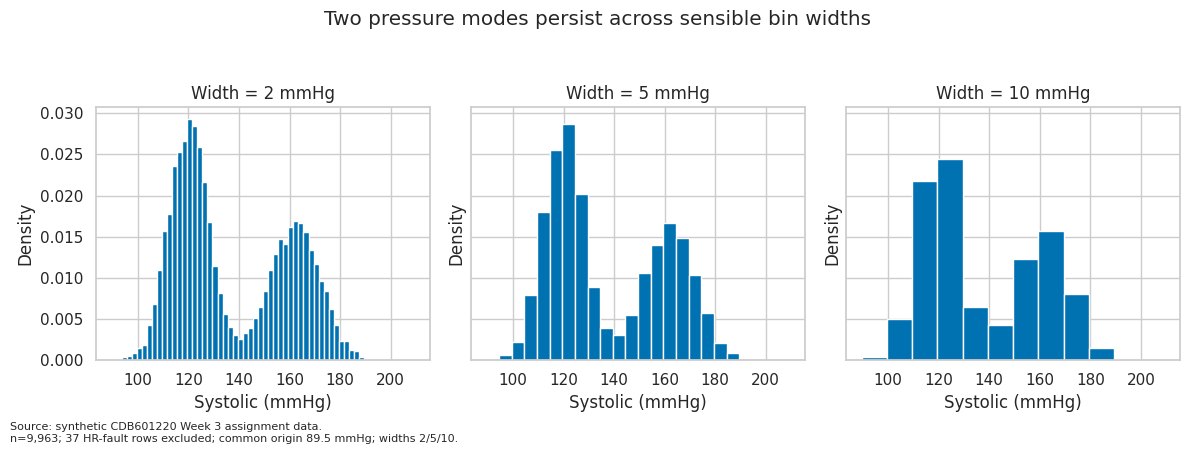

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for a, width in zip(ax, [2, 5, 10]):
    a.hist(cleaned.systolic, bins=np.arange(89.5, 209.5+width, width), density=True, color=BLUE)
    a.set(xlabel='Systolic (mmHg)', ylabel='Density', title=f'Width = {width} mmHg')
fig.suptitle('Two pressure modes persist across sensible bin widths', y=1.05)
fig.text(0.01, -0.03, SOURCE + '\n' + 'n=9,963; 37 HR-fault rows excluded; common origin 89.5 mmHg; widths 2/5/10.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

## 7. Start the required 2×2 review figure

In [19]:
fig, ax = plt.subplots(2, 2, figsize=(15, 11), gridspec_kw={'height_ratios':[1, 1.3]})
ward_order = cleaned.groupby('ward_clean').los_days.median().sort_values().index.tolist()
print('Wards ordered by median LOS:', ward_order)

Wards ordered by median LOS: ['Day Surgery', 'General Medicine', 'Cardiology', 'ICU']


### Panel 1: systolic distribution

In [20]:
ax[0,0].hist(cleaned.systolic, bins=np.arange(89.5, 214.5, 5), color=BLUE)
ax[0,0].set(xlim=(89.5,209.5), xlabel='Systolic blood pressure (mmHg)',
            ylabel='Patient records', title='Two pressure modes remain: bin width = 5 mmHg');

### Panel 2: compare ward lengths of stay

In [21]:
sns.boxplot(data=cleaned, x='ward_clean', y='los_days', order=ward_order,
            color=BLUE, width=.6, whis=1.5, showfliers=True, fliersize=2, ax=ax[0,1])
ax[0,1].set_yscale('symlog', base=10, linthresh=.1, linscale=1)
ax[0,1].set_ylim(bottom=0)
ax[0,1].set_yticks([0,.1,1,10,100], labels=['0','0.1','1','10','100'])
ax[0,1].set(xlabel='Ward (ordered by median)', ylabel='LOS (days; symlog)',
            title='ICU has the longest median stay; long tails remain')
display(cleaned.groupby('ward_clean').los_days.median().reindex(ward_order))

ward_clean
Day Surgery         0.25
General Medicine    1.26
Cardiology          1.69
ICU                 3.47
Name: los_days, dtype: float64

### Panel 3: the strongest measured pair

In [22]:
for sex, color, marker in [('F', BLUE, 'o'), ('M', ORANGE, 's')]:
    group = cleaned.loc[cleaned.sex == sex]
    ax[1,0].scatter(group.systolic, group.diastolic, s=9, alpha=.12,
                    color=color, marker=marker, linewidths=0, label=f'{sex}, n={len(group):,}')
ax[1,0].set(xlabel='Systolic (mmHg)', ylabel='Diastolic (mmHg)',
            title=f'SBP and DBP track together: r = {correlations.loc["systolic","diastolic"]:.3f}')
legend = ax[1,0].legend(markerscale=3)
for handle in legend.legend_handles:
    handle.set_alpha(1)

### Panel 4: signed, annotated correlation screen

In [23]:
sns.heatmap(correlations, mask=np.triu(np.ones_like(correlations, dtype=bool)),
            cmap='RdBu_r', vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
            xticklabels=labels, yticklabels=labels, annot_kws={'size':9},
            cbar_kws={'label':'Pearson r', 'shrink':.8}, ax=ax[1,1])
ax[1,1].set_title('Blood pressure is the strongest measured pair')
ax[1,1].tick_params(axis='x', rotation=35)
ax[1,1].tick_params(axis='y', rotation=0)

### Finish and display the complete figure inline

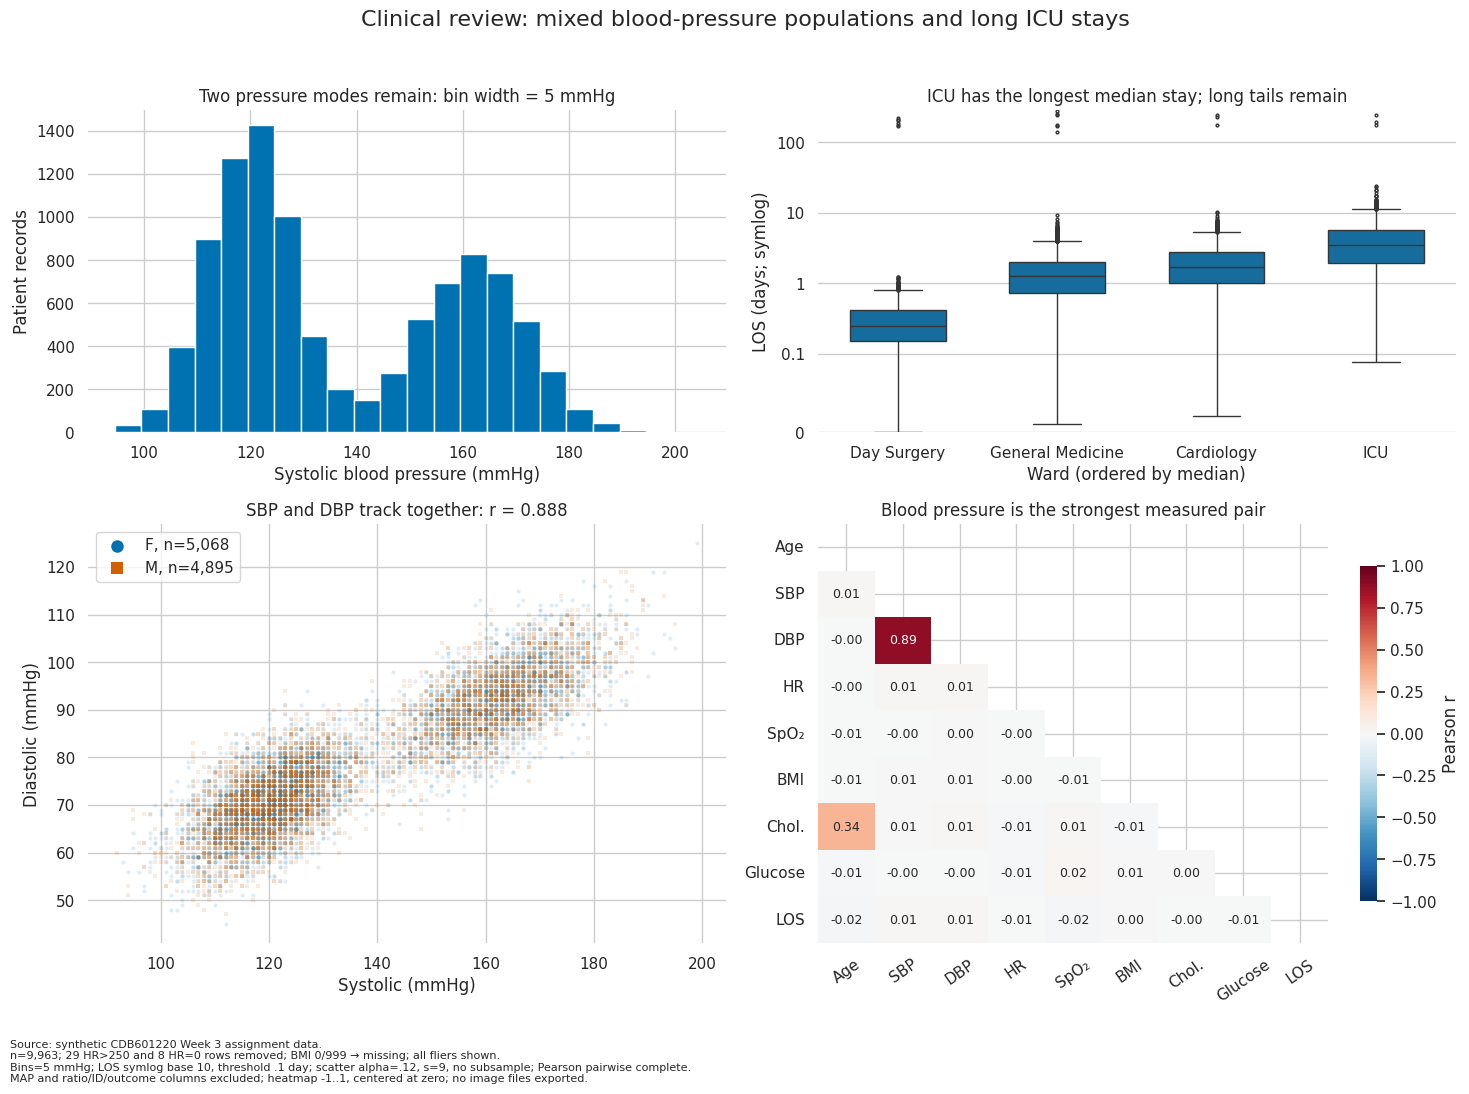

In [24]:
for a in ax.flat:
    for spine in a.spines.values():
        spine.set_visible(False)
fig.suptitle('Clinical review: mixed blood-pressure populations and long ICU stays', fontsize=16)
fig.tight_layout(rect=(0,.06,1,.96))
fig.text(.01,.005, SOURCE + '\n' +
    'n=9,963; 29 HR>250 and 8 HR=0 rows removed; BMI 0/999 → missing; all fliers shown.\n'
    'Bins=5 mmHg; LOS symlog base 10, threshold .1 day; scatter alpha=.12, s=9, no subsample; Pearson pairwise complete.\n'
    'MAP and ratio/ID/outcome columns excluded; heatmap -1..1, centered at zero; no image files exported.', fontsize=8)
display(fig)
plt.close(fig)

## 8. Sensitivity appendix: start the same figure with faulty HR rows retained

In [25]:
sensitivity = without_hr_exclusion
sensitivity_corr = sensitivity[columns].corr()
sensitivity_order = sensitivity.groupby('ward_clean').los_days.median().sort_values().index.tolist()
fig, ax = plt.subplots(2, 2, figsize=(15, 11), gridspec_kw={'height_ratios':[1,1.3]})
print('Sensitivity rows:', len(sensitivity))

Sensitivity rows: 10000


### Rebuild the two distribution panels

In [26]:
ax[0,0].hist(sensitivity.systolic, bins=np.arange(89.5,214.5,5), color=BLUE)
ax[0,0].set(xlim=(89.5,209.5), xlabel='Systolic (mmHg)', ylabel='Patient records',
            title='Two pressure modes: 5-mmHg bins; all HR rows retained')
sns.boxplot(data=sensitivity, x='ward_clean', y='los_days', order=sensitivity_order,
            color=BLUE, width=.6, whis=1.5, showfliers=True, fliersize=2, ax=ax[0,1])
ax[0,1].set_yscale('symlog', base=10, linthresh=.1, linscale=1)
ax[0,1].set_ylim(bottom=0)
ax[0,1].set_yticks([0,.1,1,10,100], labels=['0','0.1','1','10','100'])
ax[0,1].set(xlabel='Ward', ylabel='LOS (days; symlog)', title='ICU remains the ward with the longest typical stay');

### Rebuild the scatter and heatmap

In [27]:
for sex, color, marker in [('F',BLUE,'o'), ('M',ORANGE,'s')]:
    group = sensitivity.loc[sensitivity.sex == sex]
    ax[1,0].scatter(group.systolic, group.diastolic, s=9, alpha=.12,
                    color=color, marker=marker, linewidths=0, label=f'{sex}, n={len(group):,}')
ax[1,0].set(xlabel='Systolic (mmHg)', ylabel='Diastolic (mmHg)',
            title=f'SBP–DBP r = {sensitivity_corr.loc["systolic","diastolic"]:.3f}')
ax[1,0].legend(markerscale=3)
sns.heatmap(sensitivity_corr, mask=np.triu(np.ones_like(sensitivity_corr,dtype=bool)),
            cmap='RdBu_r', vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
            xticklabels=labels, yticklabels=labels, annot_kws={'size':9},
            cbar_kws={'label':'Pearson r','shrink':.8}, ax=ax[1,1])
ax[1,1].set_title('Correlation screen with all heart-rate readings')
ax[1,1].tick_params(axis='x', rotation=35)
ax[1,1].tick_params(axis='y', rotation=0)

### Display the sensitivity figure and the full audit

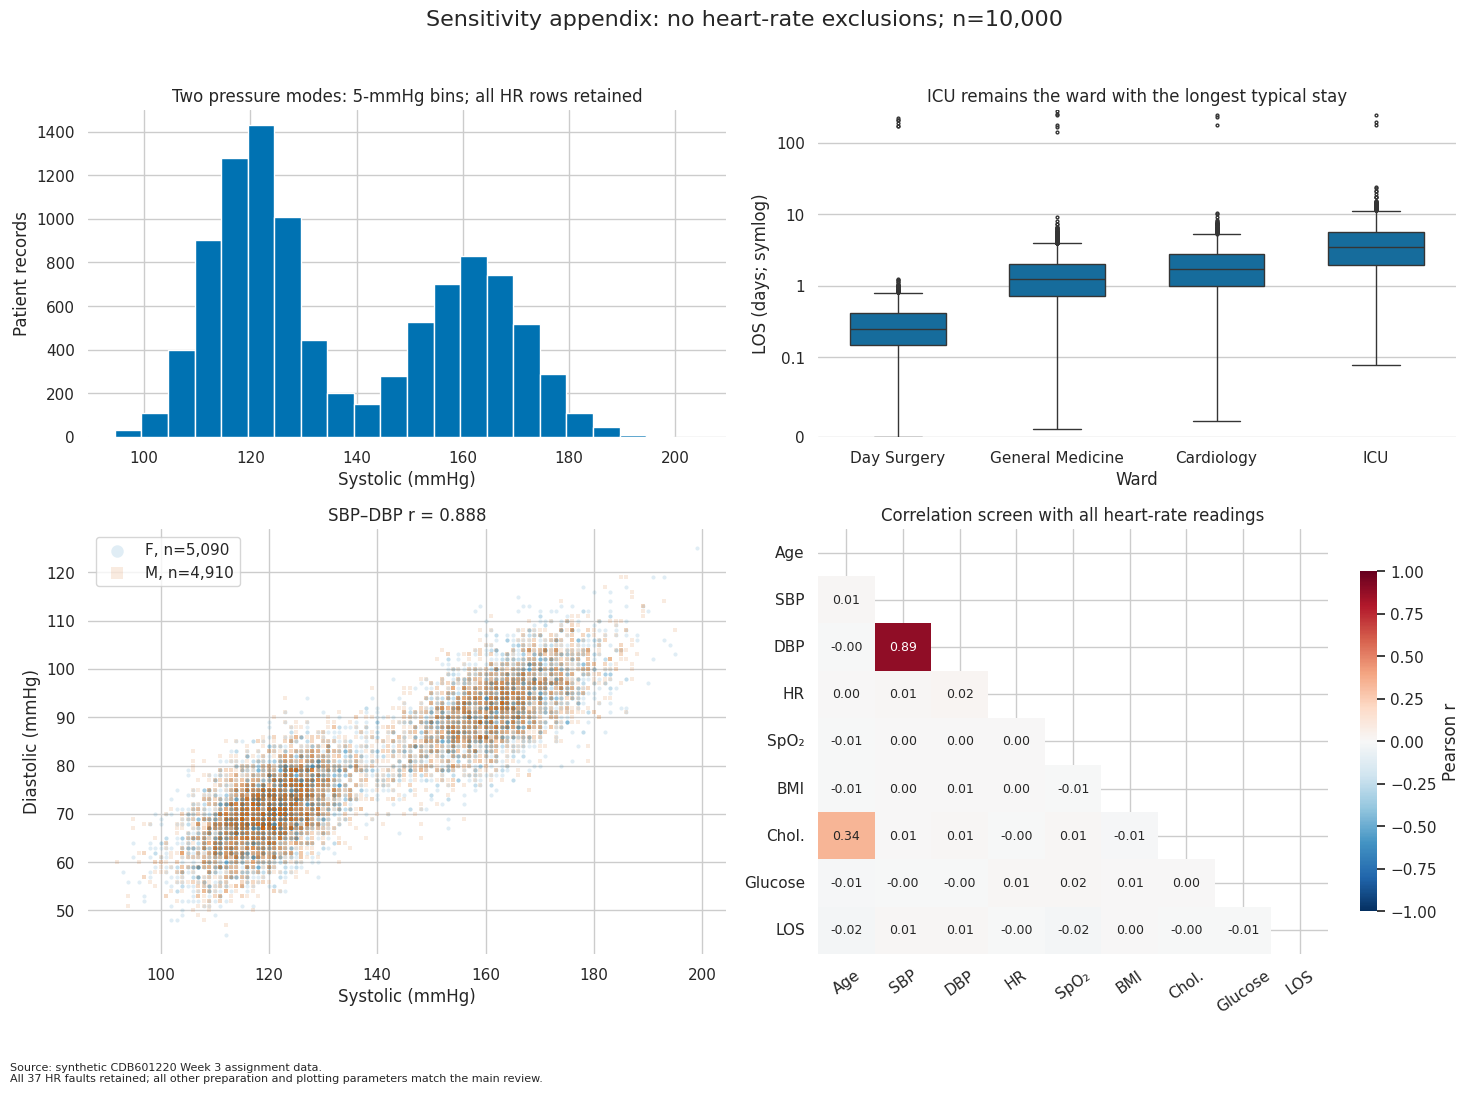

,rule,affected,rows_removed
0,12 ward spellings → 4 names,6533,0
1,Parse 3 date formats without month/day guessing,10000,0
2,BMI 0/999 → missing,486,0
3,HR >250: device faults stated in brief,29,29
4,HR <=0: invalid resting-monitor reading,8,8


In [28]:
for a in ax.flat:
    for spine in a.spines.values():
        spine.set_visible(False)
fig.suptitle('Sensitivity appendix: no heart-rate exclusions; n=10,000', fontsize=16)
fig.tight_layout(rect=(0,.05,1,.96))
fig.text(.01,.005, SOURCE + '\nAll 37 HR faults retained; all other preparation and plotting parameters match the main review.', fontsize=8)
display(fig)
plt.close(fig)
display(pd.DataFrame(cleaning_rows))